# 03 — Counting Progression: Partial (95.01%) vs Final (100.00%) Totalization
**Analysis of the Final 4.99% of Polling Sections (24,936 Sections / 6.21M Valid Votes)**

The repository captures two distinct TSE totalization milestones:
- **Partial Snapshot (`presidente_br_20261005_000211Z.json`)**: Generated by TSE on `04/10/2026 20:51:35` with **95.01% of sections counted** (`474,312 / 499,248` sections, `113,091,045` valid votes).
- **Final Snapshot (`presidente_br_20261005_211048Z.json` onwards)**: Generated by TSE on `05/10/2026 12:51:47` with **100.00% of sections counted** (`499,248 / 499,248` sections, `119,300,788` valid votes).

This notebook isolates the **exact delta of the final 4.99% of sections** (`24,936` sections, `6,547,341` total votes, `6,209,743` valid votes) and demonstrates how **Lula won 58.17%** of those late-reporting valid votes compared to **Flavio Bolsonaro's 36.02%**, cutting the 1st-round lead from **3.60M votes (3.18 pp)** down to **2.22M votes (1.86 pp)**.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120
sns.set_theme(style="whitegrid")

files = sorted(DATA_DIR.glob("presidente_br_*.json"))
doc_95 = json.loads(files[0].read_text(encoding="utf-8"))
doc_100 = json.loads(files[-1].read_text(encoding="utf-8"))

def extract_cand_dict(doc):
    out = {}
    for carg in doc["data"]["carg"]:
        for agr in carg["agr"]:
            for par in agr["par"]:
                for c in par["cand"]:
                    out[c["nmu"]] = {
                        "rank": int(c["seq"]),
                        "party": par["sg"],
                        "votes": int(c["vap"]),
                        "pct": float(c["pvapn"].replace(",", ".")),
                    }
    return out

c95 = extract_cand_dict(doc_95)
c100 = extract_cand_dict(doc_100)

vv_95 = int(doc_95["data"]["v"]["vv"])
vv_100 = int(doc_100["data"]["v"]["vv"])
vv_delta = vv_100 - vv_95

rows = []
for name, d100 in sorted(c100.items(), key=lambda x: x[1]["rank"]):
    d95 = c95[name]
    v_added = d100["votes"] - d95["votes"]
    share_of_late_votes = (v_added / vv_delta) * 100
    pct_growth = (v_added / d95["votes"]) * 100
    pp_shift = d100["pct"] - d95["pct"]
    rows.append({
        "rank": d100["rank"],
        "candidate": name,
        "party": d100["party"],
        "votes_at_95pct": d95["votes"],
        "share_at_95pct (%)": round(d95["pct"], 3),
        "votes_at_100pct": d100["votes"],
        "share_at_100pct (%)": round(d100["pct"], 3),
        "late_votes_added": v_added,
        "share_of_late_batch (%)": round(share_of_late_votes, 2),
        "vote_growth (%)": round(pct_growth, 2),
        "net_share_shift (pp)": round(pp_shift, 3),
    })

df_prog = pd.DataFrame(rows)
print(f"Valid votes at 95.01% : {vv_95:,d}")
print(f"Valid votes at 100.00%: {vv_100:,d}")
print(f"Late-counted valid votes (final 4.99% of sections): {vv_delta:,d} (+{vv_delta/vv_95*100:.2f}%)")
df_prog

Valid votes at 95.01% : 113,091,045
Valid votes at 100.00%: 119,300,788
Late-counted valid votes (final 4.99% of sections): 6,209,743 (+5.49%)


,rank,candidate,party,votes_at_95pct,share_at_95pct (%),votes_at_100pct,share_at_100pct (%),late_votes_added,share_of_late_batch (%),vote_growth (%),net_share_shift (pp)
0,1,FLAVIO BOLSONARO,PL,53867670,47.632,56104503,47.028,2236833,36.02,4.15,-0.604
1,2,LULA,PT,50267135,44.448,53879538,45.163,3612403,58.17,7.19,0.714
2,3,ESCRITOR AUGUSTO CURY,AVANTE,3299202,2.917,3448569,2.891,149367,2.41,4.53,-0.027
3,4,RENAN SANTOS,MISSÃO,2575936,2.278,2675887,2.243,99951,1.61,3.88,-0.035
4,5,RONALDO CAIADO,PSD,2514883,2.224,2605148,2.184,90265,1.45,3.59,-0.040
5,6,ZEMA,NOVO,315666,0.279,326488,0.274,10822,0.17,3.43,-0.005
6,7,SAMARA,UP,118358,0.105,122911,0.103,4553,0.07,3.85,-0.002
7,8,HERTZ DIAS,PSTU,41564,0.037,43103,0.036,1539,0.02,3.70,-0.001
8,9,CLARIANA BARAO,DC,38445,0.034,40043,0.034,1598,0.03,4.16,-0.000
9,10,EDMILSON COSTA,PCB,21530,0.019,22693,0.019,1163,0.02,5.40,-0.000


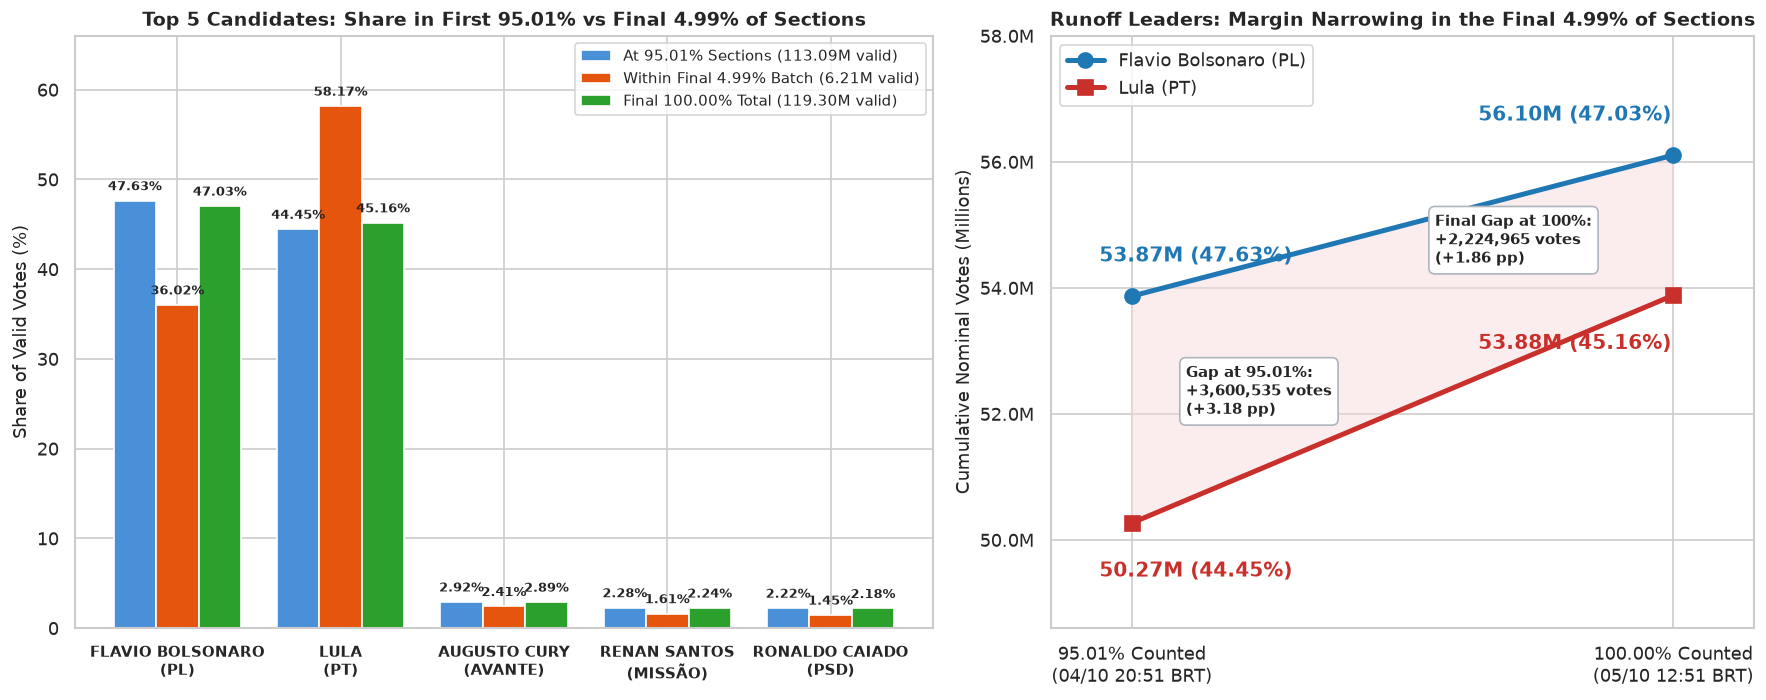

In [2]:
# Graph 1: Vote Share Comparison — First 95.01% vs Final 4.99% Batch vs Final 100.00%
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.22, 1]})

top5 = df_prog.iloc[:5].copy()
x = np.arange(len(top5))
width = 0.26

b1 = ax1.bar(x - width, top5["share_at_95pct (%)"], width, label="At 95.01% Sections (113.09M valid)", color="#4a90d9")
b2 = ax1.bar(x, top5["share_of_late_batch (%)"], width, label="Within Final 4.99% Batch (6.21M valid)", color="#e6550d")
b3 = ax1.bar(x + width, top5["share_at_100pct (%)"], width, label="Final 100.00% Total (119.30M valid)", color="#2ca02c")

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f"{h:.2f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")

short_top5 = [
    "FLAVIO BOLSONARO\n(PL)",
    "LULA\n(PT)",
    "AUGUSTO CURY\n(AVANTE)",
    "RENAN SANTOS\n(MISSÃO)",
    "RONALDO CAIADO\n(PSD)",
]
ax1.set_xticks(x)
ax1.set_xticklabels(short_top5, fontsize=9, fontweight="bold")
ax1.set_ylim(0, 66)
ax1.set_ylabel("Share of Valid Votes (%)", fontsize=10.5)
ax1.set_title("Top 5 Candidates: Share in First 95.01% vs Final 4.99% of Sections", fontsize=11.5, fontweight="bold")
ax1.legend(loc="upper right", frameon=True, fontsize=9)

# Right panel: Lead Narrowing Trajectory (Flavio Bolsonaro vs Lula)
flavio_95 = df_prog.loc[0, "votes_at_95pct"]
lula_95 = df_prog.loc[1, "votes_at_95pct"]
flavio_100 = df_prog.loc[0, "votes_at_100pct"]
lula_100 = df_prog.loc[1, "votes_at_100pct"]

stages_x = ["95.01% Counted\n(04/10 20:51 BRT)", "100.00% Counted\n(05/10 12:51 BRT)"]
ax2.plot(stages_x, [flavio_95 / 1e6, flavio_100 / 1e6], marker="o", markersize=9, linewidth=3, color="#1f77b4", label="Flavio Bolsonaro (PL)")
ax2.plot(stages_x, [lula_95 / 1e6, lula_100 / 1e6], marker="s", markersize=9, linewidth=3, color="#c9302c", label="Lula (PT)")

ax2.fill_between(
    [0, 1],
    [lula_95 / 1e6, lula_100 / 1e6],
    [flavio_95 / 1e6, flavio_100 / 1e6],
    color="#f8d7da", alpha=0.45
)

ax2.annotate(f"{flavio_95/1e6:.2f}M (47.63%)", (0, flavio_95 / 1e6), xytext=(-0.06, flavio_95 / 1e6 + 0.55), fontweight="bold", color="#1f77b4")
ax2.annotate(f"{flavio_100/1e6:.2f}M (47.03%)", (1, flavio_100 / 1e6), xytext=(0.64, flavio_100 / 1e6 + 0.55), fontweight="bold", color="#1f77b4")
ax2.annotate(f"{lula_95/1e6:.2f}M (44.45%)", (0, lula_95 / 1e6), xytext=(-0.06, lula_95 / 1e6 - 0.85), fontweight="bold", color="#c9302c")
ax2.annotate(f"{lula_100/1e6:.2f}M (45.16%)", (1, lula_100 / 1e6), xytext=(0.64, lula_100 / 1e6 - 0.85), fontweight="bold", color="#c9302c")

ax2.text(0.10, 52.0, "Gap at 95.01%:\n+3,600,535 votes\n(+3.18 pp)", fontsize=9.2, fontweight="bold", bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "#adb5bd"})
ax2.text(0.56, 54.4, "Final Gap at 100%:\n+2,224,965 votes\n(+1.86 pp)", fontsize=9.2, fontweight="bold", bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "#adb5bd"})

ax2.set_ylim(48.6, 58.0)
ax2.set_xlim(-0.15, 1.15)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:.1f}M"))
ax2.set_ylabel("Cumulative Nominal Votes (Millions)", fontsize=10.5)
ax2.set_title("Runoff Leaders: Margin Narrowing in the Final 4.99% of Sections", fontsize=11.5, fontweight="bold")
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

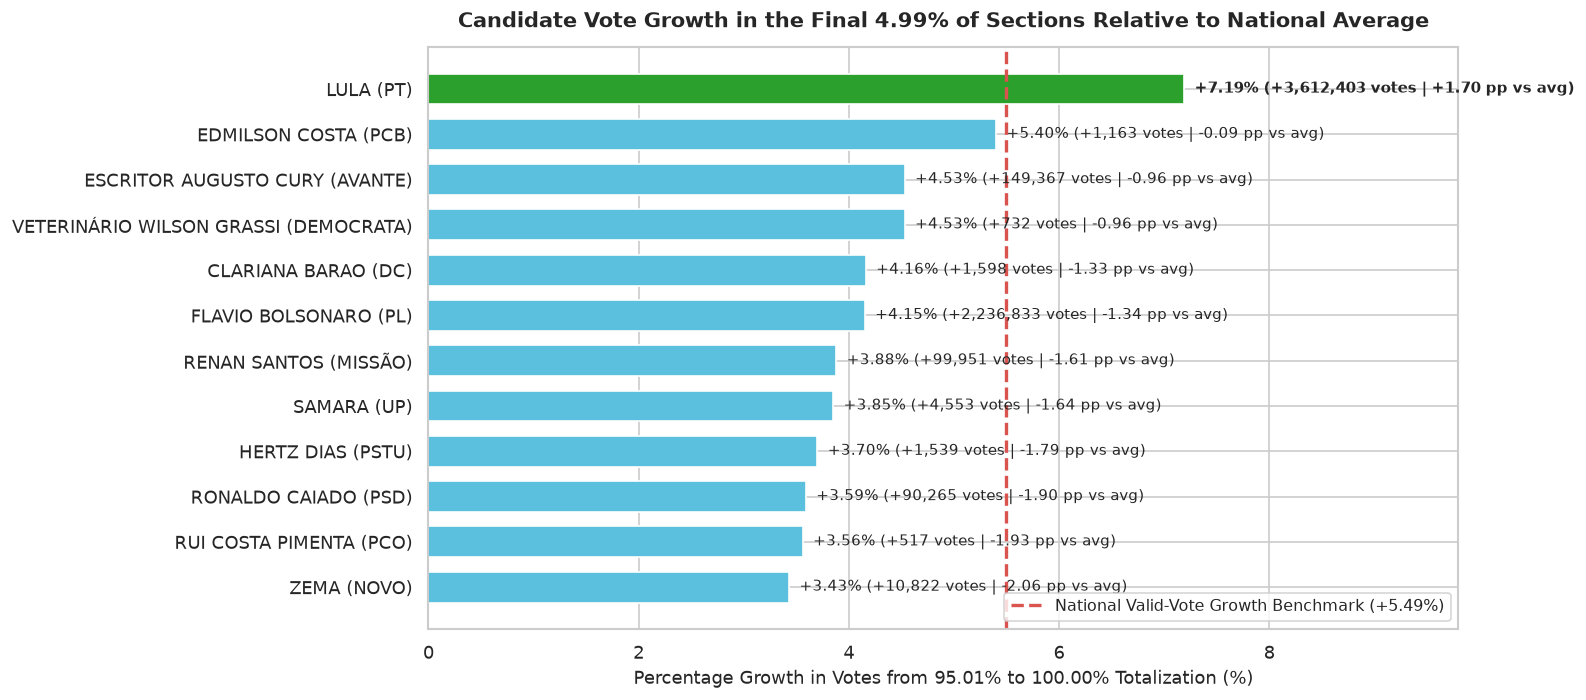

In [3]:
# Graph 2: Relative Vote Growth (%) by Candidate in the Final 4.99% of Sections vs National Average (+5.49%)
nat_growth_pct = (vv_delta / vv_95) * 100
df_growth = df_prog.sort_values("vote_growth (%)", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6))
bar_colors = ["#2ca02c" if g >= nat_growth_pct else "#5bc0de" for g in df_growth["vote_growth (%)"]]
bars = ax.barh(
    [f"{r['candidate']} ({r['party']})" for _, r in df_growth.iterrows()],
    df_growth["vote_growth (%)"],
    color=bar_colors,
    edgecolor="white",
    height=0.68,
)

ax.axvline(nat_growth_pct, color="#d9534f", linestyle="--", linewidth=2,
           label=f"National Valid-Vote Growth Benchmark (+{nat_growth_pct:.2f}%)")

for bar, (_, row) in zip(bars, df_growth.iterrows()):
    w = bar.get_width()
    diff_vs_nat = row["vote_growth (%)"] - nat_growth_pct
    sign = "+" if diff_vs_nat >= 0 else ""
    ax.text(
        w + 0.1, bar.get_y() + bar.get_height() / 2,
        f"+{row['vote_growth (%)']:.2f}% (+{row['late_votes_added']:,d} votes | {sign}{diff_vs_nat:.2f} pp vs avg)",
        va="center", fontsize=8.8,
        fontweight="bold" if row["vote_growth (%)"] >= nat_growth_pct else "normal"
    )

ax.set_xlim(0, 9.8)
ax.set_xlabel("Percentage Growth in Votes from 95.01% to 100.00% Totalization (%)", fontsize=10.5)
ax.set_title("Candidate Vote Growth in the Final 4.99% of Sections Relative to National Average", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

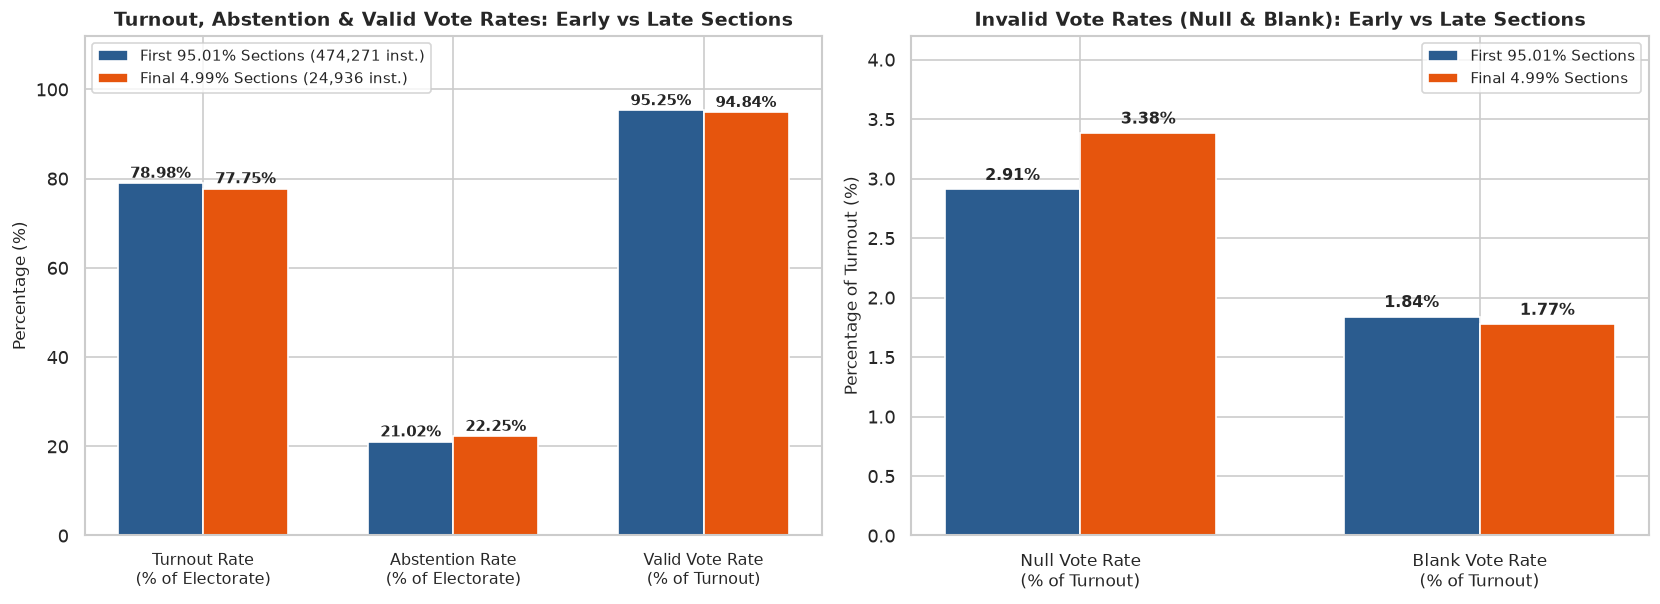

In [4]:
# Graph 3: Electoral Behavior in First 95.01% of Sections vs Final 4.99% of Sections
e95, v95, s95 = doc_95["data"]["e"], doc_95["data"]["v"], doc_95["data"]["s"]
e100, v100, s100 = doc_100["data"]["e"], doc_100["data"]["v"], doc_100["data"]["s"]

# First 95.01% rates
turnout_95 = int(e95["c"]) / int(e95["esi"]) * 100
abst_95 = int(e95["a"]) / int(e95["esi"]) * 100
valid_95 = int(v95["vv"]) / int(v95["tv"]) * 100
null_95 = int(v95["tvn"]) / int(v95["tv"]) * 100
blank_95 = int(v95["vb"]) / int(v95["tv"]) * 100

# Final 4.99% batch counts & rates
esi_late = int(e100["esi"]) - int(e95["esi"])
c_late = int(e100["c"]) - int(e95["c"])
a_late = int(e100["a"]) - int(e95["a"])
tv_late = int(v100["tv"]) - int(v95["tv"])
vv_late = int(v100["vv"]) - int(v95["vv"])
tvn_late = int(v100["tvn"]) - int(v95["tvn"])
vb_late = int(v100["vb"]) - int(v95["vb"])

turnout_late = c_late / esi_late * 100
abst_late = a_late / esi_late * 100
valid_late = vv_late / tv_late * 100
null_late = tvn_late / tv_late * 100
blank_late = vb_late / tv_late * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Turnout vs Abstention & ValidVote Share
cats1 = ["Turnout Rate\n(% of Electorate)", "Abstention Rate\n(% of Electorate)", "Valid Vote Rate\n(% of Turnout)"]
vals_early1 = [turnout_95, abst_95, valid_95]
vals_late1 = [turnout_late, abst_late, valid_late]

x1 = np.arange(len(cats1))
w = 0.34
b_e1 = ax1.bar(x1 - w/2, vals_early1, w, label="First 95.01% Sections (474,271 inst.)", color="#2b5c8f")
b_l1 = ax1.bar(x1 + w/2, vals_late1, w, label="Final 4.99% Sections (24,936 inst.)", color="#e6550d")
for bars in (b_e1, b_l1):
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 1.2, f"{h:.2f}%", ha="center", fontsize=9, fontweight="bold")
ax1.set_xticks(x1)
ax1.set_xticklabels(cats1, fontsize=9.5)
ax1.set_ylim(0, 112)
ax1.set_ylabel("Percentage (%)", fontsize=10)
ax1.set_title("Turnout, Abstention & Valid Vote Rates: Early vs Late Sections", fontsize=11.5, fontweight="bold")
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# Right: Blank & Null Rates
cats2 = ["Null Vote Rate\n(% of Turnout)", "Blank Vote Rate\n(% of Turnout)"]
vals_early2 = [null_95, blank_95]
vals_late2 = [null_late, blank_late]

x2 = np.arange(len(cats2))
b_e2 = ax2.bar(x2 - w/2, vals_early2, w, label="First 95.01% Sections", color="#2b5c8f")
b_l2 = ax2.bar(x2 + w/2, vals_late2, w, label="Final 4.99% Sections", color="#e6550d")
for bars in (b_e2, b_l2):
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.08, f"{h:.2f}%", ha="center", fontsize=9.5, fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(cats2, fontsize=10)
ax2.set_ylim(0, 4.2)
ax2.set_ylabel("Percentage of Turnout (%)", fontsize=10)
ax2.set_title("Invalid Vote Rates (Null & Blank): Early vs Late Sections", fontsize=11.5, fontweight="bold")
ax2.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()